# **Tutorial 04 - Singular Value Decomposition**: Supplementary Interactive Material

-------------------------------------------------------------------------


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


## Visualizing the SVD:

We can visualize the action of the SVD: 

$$ A = U\Sigma V^T$$

The Singular Value Decomposition (SVD) factors any matrix into three simple geometric transformations:

$V^T$: A rotation or reflection of the input space.

$\Sigma$: A scaling that stretches or compresses space along the principal axes (the singular values).

$U$: A final rotation or reflection of the output space.
    

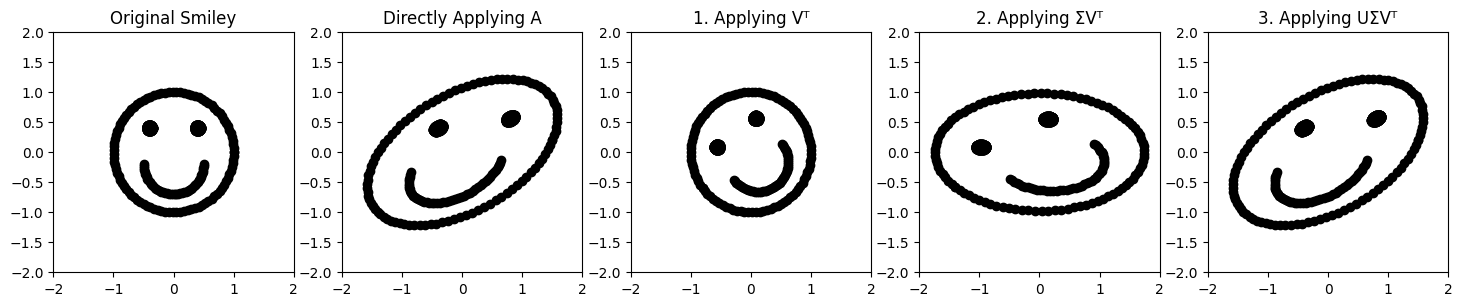

In [3]:

# --- Arbitrary Matrix (Shear + Scale) ---
A = np.array([[1.5, 0.5],
              [0.2, 1.2]])

# Compute SVD
U, S, Vt = np.linalg.svd(A)
Sigma = np.diag(S)

# --- Smiley Face Point Cloud ---
t = np.linspace(0, 2 * np.pi, 100)
face_x = np.cos(t)
face_y = np.sin(t)
left_eye_x = -0.4 + 0.05 * np.cos(t)
left_eye_y =  0.4 + 0.05 * np.sin(t)
right_eye_x = 0.4 + 0.05 * np.cos(t)
right_eye_y = 0.4 + 0.05 * np.sin(t)
smile_t = np.linspace(0, np.pi, 50)
smile_x = 0.5 * np.cos(smile_t)
smile_y = -0.5 * np.sin(smile_t) - 0.2

points = np.vstack((
    np.column_stack((face_x, face_y)),
    np.column_stack((left_eye_x, left_eye_y)),
    np.column_stack((right_eye_x, right_eye_y)),
    np.column_stack((smile_x, smile_y))
))

# --- Apply Transformations ---
points_A = (A @ points.T).T
points_Vt = (Vt @ points.T).T
points_Sigma = (Sigma @ points_Vt.T).T
points_USigma = (U @ points_Sigma.T).T

# --- Plotting ---
fig, axes = plt.subplots(1, 5, figsize=(18, 6))

titles = ["Original Smiley", "Directly Applying A", "1. Applying Vᵀ", "2. Applying ΣVᵀ", "3. Applying UΣVᵀ"]
point_sets = [points, points_A, points_Vt, points_Sigma, points_USigma]

for ax, title, pts in zip(axes, titles, point_sets):
    ax.scatter(pts[:, 0], pts[:, 1], color='black')
    ax.set_title(title)
    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)
    ax.set_aspect('equal')
    ax.grid(False)

plt.show()


## Single-image SVD compression


For one grayscale image, rows and columns represent spatial pixel positions, so the image is a matrix $A\in\mathbb{R}^{m\times n}$. Its SVD is

$$
A=U\Sigma V^\mathsf{T}=\sum_{i=1}^{r}\sigma_i u_i v_i^\mathsf{T}.
$$

Each outer product is a rank-one image pattern. Keeping the first $k$ terms gives an approximation at the original resolution:

$$
A_k=\sum_{i=1}^{k}\sigma_i u_i v_i^\mathsf{T}.
$$

A rank-$k$ approximation stores $k(m+n+1)$ values, compared with $mn$ pixel values in the full image. The cell below shows this tradeoff for the image loaded from the course data folder.


In [4]:
# --- Load Your JPG Image ---
image = Image.open('../Data/Beltrami.jpg').convert('L')  # 'L' converts to grayscale
image_np = np.array(image) / 255.0  # Normalize to [0, 1] for display

In [ ]:
# Economy SVD of the single grayscale image.
U, S, Vt = np.linalg.svd(image_np, full_matrices=False)

# Reconstruct with the first k singular values and vectors.
def low_rank_approx(U, S, Vt, k):
    return (U[:, :k] * S[:k]) @ Vt[:k, :]

m, n = image_np.shape
ranks = [5, 10, 20, 50]
fig, axes = plt.subplots(1, len(ranks), figsize=(14, 4))

for ax, k in zip(axes, ranks):
    approximation = low_rank_approx(U, S, Vt, k)
    storage_ratio = (m * n) / (k * (m + n + 1))
    ax.imshow(approximation, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'Rank {k} ({storage_ratio:.1f}:1)')
    ax.axis('off')

plt.suptitle(f'Single-image SVD compression ({m} × {n} pixels)')
plt.tight_layout()
plt.show()


## Eigenfaces: PCA across a collection of faces

For eigenfaces, each row is one flattened face and each column is a pixel position. The Olivetti dataset has 400 grayscale face images, each 64 × 64 pixels, so its data matrix has 400 rows and 4096 columns. Centering subtracts the mean face from every row.

For the centered matrix, the SVD gives

$$
X_c=U\Sigma V^\mathsf{T}=\sum_i \sigma_i u_i v_i^\mathsf{T}.
$$

Each outer product contributes one shared pixel pattern across all samples, weighted separately for each face. The vector $v_i$ reshaped to 64 × 64 is an eigenface. For face $j$, its weight is $a_{ji}=\sigma_i u_{ji}$, so

$$
x_j \approx \mu+\sum_{i=1}^{k}a_{ji}v_i^\mathsf{T}.
$$

This is the same rank-one sum as single-image SVD, but the matrix rows now index faces and its columns index pixels. The code displays five samples, the mean face and leading eigenfaces, then one face reconstructed with different numbers of components. Scikit-learn downloads and caches the dataset on first use.


In [ ]:
from sklearn.datasets import fetch_olivetti_faces

# Each row is one face; each column is one pixel position.
faces = fetch_olivetti_faces(shuffle=True, random_state=0)
X_faces = faces.data
image_shape = faces.images.shape[1:]

# Start by looking at five randomly selected examples.
rng_faces = np.random.default_rng(7)
example_indices = rng_faces.choice(len(faces.images), size=5, replace=False)
fig, axes = plt.subplots(1, 5, figsize=(11, 3))
for ax, index in zip(axes, example_indices):
    ax.imshow(faces.images[index], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'Sample {index}')
    ax.axis('off')
plt.suptitle('Five randomly selected Olivetti faces')
plt.tight_layout()
plt.show()

# Center across face samples and compute the SVD.
mean_face = X_faces.mean(axis=0)
X_faces_centered = X_faces - mean_face
U_faces, S_faces, Vt_faces = np.linalg.svd(X_faces_centered, full_matrices=False)

# Reshape principal directions into eigenface images.
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
axes[0, 0].imshow(mean_face.reshape(image_shape), cmap='gray')
axes[0, 0].set_title('Mean face')
axes[0, 0].axis('off')
for i, ax in enumerate(axes.flat[1:]):
    component = Vt_faces[i].reshape(image_shape)
    variance_fraction = S_faces[i]**2 / np.sum(S_faces**2)
    ax.imshow(component, cmap='RdBu_r')
    ax.set_title(f'PC {i + 1} ({variance_fraction:.1%})')
    ax.axis('off')
plt.suptitle('Leading eigenfaces')
plt.tight_layout()
plt.show()

# Reconstruct one face from the mean plus weighted eigenfaces.
sample_index = 0
face_centered = X_faces_centered[sample_index]
ks = [1, 5, 20, 100]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(12, 3))
axes[0].imshow(X_faces[sample_index].reshape(image_shape), cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Original')
axes[0].axis('off')
for ax, k in zip(axes[1:], ks):
    scores = face_centered @ Vt_faces[:k].T
    reconstruction = scores @ Vt_faces[:k] + mean_face
    ax.imshow(reconstruction.reshape(image_shape), cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'{k} components')
    ax.axis('off')
plt.suptitle('Reconstruction from weighted eigenfaces')
plt.tight_layout()
plt.show()

explained = S_faces**2 / np.sum(S_faces**2)
print(f'First 10 components capture {explained[:10].sum():.1%} of the variation across faces.')


> **Exercise:** How does the reconstruction change as more eigenfaces are included? What kinds of variation do the leading eigenfaces represent?
